# Project Eco Drive
## Machine learning Pipeline for pre-owned Electric Vehicle Market Analysis

### Objectives
This project develops an end-to-end machine learning pipeline to:

1. Predict whether a pre-owned vehicle will have high Demand using Classification.

2. Predict the Resale price of a pre-owned electric vehicle using Regression.

3. Clean and preprocess EV market data.

4. Perform exploratory data analysis and outlier treatment.

5. Engineer meaningful EV-related features.

6. Apply encoding standardization, feature selection, and cross-validation.

7. Train, tune and compare multiple machine learning models.

8. Recommend the best -performing model based on evaluation results.

In [31]:
# ============================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    RandomForestRegressor
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

print("all llibraries imported successfully!")

all llibraries imported successfully!


# Module 1: Data Exploration, Wrangling, and Cleaning

This module focuses on loading and understanding the pre-owned EV dataset, identifying missing values, treating numerical and categorical null values, detecting unrealistic anomalies using the IQR method, and performing initial exploratory data analysis.

In [32]:
# ============================================================
# CREATE SYNTHETIC PRE-OWNED EV DATASET
# ============================================================

np.random.seed(42)

n_vehicles = 600

df = pd.DataFrame({
    "Brand": np.random.choice(
        ["Tesla", "Tata", "MG", "Hyundai", "Kia", "BYD"],
        n_vehicles
    ),

    "Vehicle_Age_Years": np.random.randint(
        1, 11, n_vehicles
    ),

    "Battery_Capacity_kWh": np.random.uniform(
        25, 100, n_vehicles
    ).round(2),

    "Battery_Health_Percent": np.random.uniform(
        60, 100, n_vehicles
    ).round(2),

    "Charging_Speed_kW": np.random.uniform(
        20, 250, n_vehicles
    ).round(2),

    "Odometer_km": np.random.randint(
        5000, 150001, n_vehicles
    ),

    "Battery_Chemistry": np.random.choice(
        ["LFP", "NMC", "NCA"],
        n_vehicles
    ),

    "Region": np.random.choice(
        ["North", "South", "East", "West", "Central"],
        n_vehicles
    )
})

# Create meaningful resale price
df["Resale_Price_USD"] = (
    12000
    + (df["Battery_Capacity_kWh"] * 250)
    + (df["Battery_Health_Percent"] * 180)
    - (df["Vehicle_Age_Years"] * 1200)
    - (df["Odometer_km"] * 0.06)
    + np.random.normal(0, 2500, n_vehicles)
).clip(3000, 60000).round(2)

# Create High Demand target
demand_score = (
    (df["Battery_Health_Percent"] * 0.35)
    + (df["Charging_Speed_kW"] * 0.08)
    - (df["Vehicle_Age_Years"] * 1.5)
    - (df["Odometer_km"] / 20000)
)

demand_threshold = demand_score.median()

df["High_Demand"] = (
    demand_score > demand_threshold
).astype(int)

print("EcoDrive Dataset Created Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

EcoDrive Dataset Created Successfully!
Dataset Shape: (600, 10)


,Brand,Vehicle_Age_Years,Battery_Capacity_kWh,Battery_Health_Percent,Charging_Speed_kW,Odometer_km,Battery_Chemistry,Region,Resale_Price_USD,High_Demand
0,Hyundai,1,26.90,73.08,222.30,79083,NMC,North,26898.00,1
1,Kia,4,36.71,86.70,220.23,65948,NCA,Central,31230.77,1
2,MG,9,78.70,92.31,74.92,31672,NCA,South,37382.48,0
3,Kia,3,74.42,90.49,123.79,9213,LFP,West,37473.51,1
4,Kia,9,27.03,91.91,246.55,146365,LFP,West,16660.20,1


In [33]:
# ============================================================
# INTRODUCE MISSING VALUES AND DATA ANOMALIES
# ============================================================

np.random.seed(42)

# Missing numerical values
battery_missing = np.random.choice(
    df.index, size=25, replace=False
)
df.loc[battery_missing, "Battery_Health_Percent"] = np.nan

odometer_missing = np.random.choice(
    df.index, size=20, replace=False
)
df.loc[odometer_missing, "Odometer_km"] = np.nan

price_missing = np.random.choice(
    df.index, size=20, replace=False
)
df.loc[price_missing, "Resale_Price_USD"] = np.nan

# Missing categorical values
chemistry_missing = np.random.choice(
    df.index, size=15, replace=False
)
df.loc[chemistry_missing, "Battery_Chemistry"] = np.nan

# Introduce unrealistic pricing anomalies
price_outliers = np.random.choice(
    df.dropna(subset=["Resale_Price_USD"]).index,
    size=8,
    replace=False
)

df.loc[price_outliers, "Resale_Price_USD"] = [
    250000,
    300000,
    275000,
    400000,
    350000,
    500000,
    450000,
    325000
]

print("Missing values and anomalies introduced successfully!")

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

Missing values and anomalies introduced successfully!

Missing Values:
Brand                      0
Vehicle_Age_Years          0
Battery_Capacity_kWh       0
Battery_Health_Percent    25
Charging_Speed_kW          0
Odometer_km               20
Battery_Chemistry         15
Region                     0
Resale_Price_USD          20
High_Demand                0
dtype: int64

Dataset Shape: (600, 10)


In [34]:
# ============================================================
# DATASET INSPECTION
# ============================================================

print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (600, 10)

Data Types:
Brand                      object
Vehicle_Age_Years           int64
Battery_Capacity_kWh      float64
Battery_Health_Percent    float64
Charging_Speed_kW         float64
Odometer_km               float64
Battery_Chemistry          object
Region                     object
Resale_Price_USD          float64
High_Demand                 int64
dtype: object

Missing Values:
Brand                      0
Vehicle_Age_Years          0
Battery_Capacity_kWh       0
Battery_Health_Percent    25
Charging_Speed_kW          0
Odometer_km               20
Battery_Chemistry         15
Region                     0
Resale_Price_USD          20
High_Demand                0
dtype: int64

Statistical Summary:


,Vehicle_Age_Years,Battery_Capacity_kWh,Battery_Health_Percent,Charging_Speed_kW,Odometer_km,Resale_Price_USD,High_Demand
count,600.000000,600.000000,575.000000,600.000000,580.000000,580.000000,600.000000
mean,5.431667,62.936817,79.586122,135.853650,76978.003448,35496.423483,0.500000
std,2.895855,22.360683,11.454803,65.923445,42142.875630,39926.345770,0.500417
min,1.000000,25.370000,60.130000,20.030000,5174.000000,10520.760000,0.000000
25%,3.000000,42.447500,69.535000,84.005000,39127.000000,25407.937500,0.000000
50%,5.000000,63.950000,79.860000,135.955000,76098.500000,31059.090000,0.500000
75%,8.000000,82.337500,89.315000,192.365000,112438.250000,37099.335000,1.000000
max,10.000000,99.960000,99.930000,249.500000,149941.000000,500000.000000,1.000000


In [35]:
# ============================================================
# MISSING VALUE IMPUTATION
# ============================================================

# Numerical columns -> Median
numerical_missing_cols = [
    "Battery_Health_Percent",
    "Odometer_km",
    "Resale_Price_USD"
]

for column in numerical_missing_cols:
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)
    print(f"{column} filled with median: {median_value:.2f}")

# Categorical column -> Mode
chemistry_mode = df["Battery_Chemistry"].mode()[0]

df["Battery_Chemistry"] = df[
    "Battery_Chemistry"
].fillna(chemistry_mode)

print(
    f"\nBattery_Chemistry filled with mode: "
    f"{chemistry_mode}"
)

print("\nMissing Values After Imputation:")
print(df.isnull().sum())

print(
    "\nTotal Missing Values:",
    df.isnull().sum().sum()
)

Battery_Health_Percent filled with median: 79.86
Odometer_km filled with median: 76098.50
Resale_Price_USD filled with median: 31059.09

Battery_Chemistry filled with mode: NCA

Missing Values After Imputation:
Brand                     0
Vehicle_Age_Years         0
Battery_Capacity_kWh      0
Battery_Health_Percent    0
Charging_Speed_kW         0
Odometer_km               0
Battery_Chemistry         0
Region                    0
Resale_Price_USD          0
High_Demand               0
dtype: int64

Total Missing Values: 0


In [36]:
# ============================================================
# IQR OUTLIER DETECTION - RESALE PRICE
# ============================================================

Q1 = df["Resale_Price_USD"].quantile(0.25)
Q3 = df["Resale_Price_USD"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

price_outliers_detected = df[
    (df["Resale_Price_USD"] < lower_bound) |
    (df["Resale_Price_USD"] > upper_bound)
]

print("\nNumber of Price Outliers:",
      len(price_outliers_detected))

display(
    price_outliers_detected[
        ["Brand", "Vehicle_Age_Years",
         "Resale_Price_USD"]
    ].sort_values(
        "Resale_Price_USD",
        ascending=False
    )
)

Q1: 25565.06
Q3: 36817.91
IQR: 11252.85
Lower Bound: 8685.79
Upper Bound: 53697.19

Number of Price Outliers: 9


,Brand,Vehicle_Age_Years,Resale_Price_USD
554,Tata,1,500000.00
94,Hyundai,6,450000.00
183,BYD,1,400000.00
105,Hyundai,10,350000.00
34,BYD,7,325000.00
506,BYD,3,300000.00
454,Tata,1,275000.00
468,BYD,8,250000.00
205,Tata,1,54254.59


In [37]:
# ============================================================
# REMOVE RESALE PRICE OUTLIERS
# ============================================================

rows_before = len(df)

df = df[
    (df["Resale_Price_USD"] >= lower_bound) &
    (df["Resale_Price_USD"] <= upper_bound)
].copy()

df.reset_index(drop=True, inplace=True)

rows_after = len(df)

print("Rows Before Cleaning:", rows_before)
print("Rows Removed:", rows_before - rows_after)
print("Rows After Cleaning:", rows_after)

print(
    "\nMaximum Resale Price After Cleaning:",
    round(df["Resale_Price_USD"].max(), 2)
)

Rows Before Cleaning: 600
Rows Removed: 9
Rows After Cleaning: 591

Maximum Resale Price After Cleaning: 52439.7


In [38]:
# ============================================================
# IQR OUTLIER CHECK - ODOMETER
# ============================================================

Q1_odo = df["Odometer_km"].quantile(0.25)
Q3_odo = df["Odometer_km"].quantile(0.75)

IQR_odo = Q3_odo - Q1_odo

lower_odo = Q1_odo - (1.5 * IQR_odo)
upper_odo = Q3_odo + (1.5 * IQR_odo)

odometer_outliers = df[
    (df["Odometer_km"] < lower_odo) |
    (df["Odometer_km"] > upper_odo)
]

print("Odometer Lower Bound:", round(lower_odo, 2))
print("Odometer Upper Bound:", round(upper_odo, 2))

print(
    "\nNumber of Odometer Outliers:",
    len(odometer_outliers)
)

if len(odometer_outliers) > 0:
    display(
        odometer_outliers[
            ["Brand", "Vehicle_Age_Years", "Odometer_km"]
        ]
    )
else:
    print("No unrealistic odometer outliers detected.")

Odometer Lower Bound: -67602.75
Odometer Upper Bound: 219419.25

Number of Odometer Outliers: 0
No unrealistic odometer outliers detected.


In [39]:
# ============================================================
# FINAL DATA CLEANING CHECK
# ============================================================

print("Final Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())

print("\nResale Price Range:")
print(
    round(df["Resale_Price_USD"].min(), 2),
    "to",
    round(df["Resale_Price_USD"].max(), 2)
)

print("\nOdometer Range:")
print(
    round(df["Odometer_km"].min(), 2),
    "to",
    round(df["Odometer_km"].max(), 2)
)

Final Dataset Shape: (591, 10)
Total Missing Values: 0

Resale Price Range:
10520.76 to 52439.7

Odometer Range:
5174.0 to 149941.0


# Module 2: Feature Engineering, Encoding, and Scaling

This module creates domain-driven EV features, converts categorical variables into machine-readable numerical features using One-Hot Encoding, and standardizes continuous numerical variables using Z-Score Standardization.

In [40]:
# ============================================================
# FEATURE ENGINEERING - BATTERY CONDITION INDEX
# ============================================================

df["Battery_Condition_Index"] = (
    df["Battery_Health_Percent"]
    * df["Battery_Capacity_kWh"]
) / (df["Vehicle_Age_Years"] + 1)

print("New Feature Created: Battery_Condition_Index")

display(
    df[
        [
            "Battery_Health_Percent",
            "Battery_Capacity_kWh",
            "Vehicle_Age_Years",
            "Battery_Condition_Index"
        ]
    ].head()
)

New Feature Created: Battery_Condition_Index


,Battery_Health_Percent,Battery_Capacity_kWh,Vehicle_Age_Years,Battery_Condition_Index
0,73.08,26.90,1,982.92600
1,86.70,36.71,4,636.55140
2,79.86,78.70,9,628.49820
3,90.49,74.42,3,1683.56645
4,91.91,27.03,9,248.43273


In [41]:
# ============================================================
# SEPARATE FEATURES AND TARGET VARIABLES
# ============================================================

X = df.drop(
    columns=[
        "High_Demand",
        "Resale_Price_USD"
    ]
)

y_classification = df["High_Demand"]
y_regression = df["Resale_Price_USD"]

print("Feature Dataset Shape:", X.shape)
print("Classification Target Shape:", y_classification.shape)
print("Regression Target Shape:", y_regression.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Feature Dataset Shape: (591, 9)
Classification Target Shape: (591,)
Regression Target Shape: (591,)

Feature Columns:
['Brand', 'Vehicle_Age_Years', 'Battery_Capacity_kWh', 'Battery_Health_Percent', 'Charging_Speed_kW', 'Odometer_km', 'Battery_Chemistry', 'Region', 'Battery_Condition_Index']


In [42]:
# ============================================================
# IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Vehicle_Age_Years', 'Battery_Capacity_kWh', 'Battery_Health_Percent', 'Charging_Speed_kW', 'Odometer_km', 'Battery_Condition_Index']

Categorical Features:
['Brand', 'Battery_Chemistry', 'Region']


In [43]:
# ============================================================
# ONE-HOT ENCODING + Z-SCORE STANDARDIZATION
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

X_processed = preprocessor.fit_transform(X)

print("Original Feature Shape:", X.shape)
print("Processed Feature Shape:", X_processed.shape)

Original Feature Shape: (591, 9)
Processed Feature Shape: (591, 20)


In [44]:
# ============================================================
# CREATE PROCESSED DATAFRAME
# ============================================================

encoded_categorical_features = (
    preprocessor
    .named_transformers_["cat"]
    .get_feature_names_out(categorical_features)
)

all_feature_names = (
    numerical_features
    + list(encoded_categorical_features)
)

X_processed_df = pd.DataFrame(
    X_processed,
    columns=all_feature_names,
    index=X.index
)

print("Processed Dataset Shape:", X_processed_df.shape)

display(X_processed_df.head())

Processed Dataset Shape: (591, 20)


,Vehicle_Age_Years,Battery_Capacity_kWh,Battery_Health_Percent,Charging_Speed_kW,Odometer_km,Battery_Condition_Index,Brand_BYD,Brand_Hyundai,Brand_Kia,Brand_MG,Brand_Tata,Brand_Tesla,Battery_Chemistry_LFP,Battery_Chemistry_NCA,Battery_Chemistry_NMC,Region_Central,Region_East,Region_North,Region_South,Region_West
0,-1.544178,-1.606343,-0.578167,1.306545,0.048166,-0.070399,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,-0.503179,-1.168211,0.633067,1.275104,-0.268784,-0.486467,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,1.231820,0.707139,0.024782,-0.931981,-1.095870,-0.496140,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.850179,0.515986,0.970113,-0.189704,-1.637810,0.771215,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,1.231820,-1.600537,1.096395,1.674874,1.671693,-0.952678,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


# Module 3: Feature Selection and Validation Setup

This module applies Recursive Feature Elimination (RFE) to identify the most predictive features for High Demand classification. Stratified K-Fold Cross-Validation is used to preserve the target class distribution across folds and provide a reliable model evaluation strategy.

In [45]:
# ============================================================
# RECURSIVE FEATURE ELIMINATION (RFE)
# ============================================================

rfe_estimator = LogisticRegression(
    max_iter=1000,
    random_state=42
)

rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=10
)

rfe.fit(
    X_processed_df,
    y_classification
)

selected_features = X_processed_df.columns[
    rfe.support_
].tolist()

print("Number of Selected Features:", len(selected_features))

print("\nSelected Features:")
for feature in selected_features:
    print("-", feature)

Number of Selected Features: 10

Selected Features:
- Vehicle_Age_Years
- Battery_Capacity_kWh
- Battery_Health_Percent
- Charging_Speed_kW
- Odometer_km
- Battery_Condition_Index
- Brand_BYD
- Battery_Chemistry_LFP
- Region_East
- Region_South


In [46]:
# ============================================================
# SELECTED FEATURE DATASET + STRATIFIED K-FOLD
# ============================================================

X_selected = X_processed_df[selected_features]

stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_selected,
    y_classification,
    cv=stratified_kfold,
    scoring="accuracy"
)

print("Selected Feature Dataset Shape:", X_selected.shape)

print("\nAccuracy for Each Fold:")
print(np.round(cv_scores, 4))

print(
    "\nMean CV Accuracy:",
    round(cv_scores.mean(), 4)
)

print(
    "Standard Deviation:",
    round(cv_scores.std(), 4)
)

Selected Feature Dataset Shape: (591, 10)

Accuracy for Each Fold:
[0.9832 0.9746 0.9746 0.9831 0.9746]

Mean CV Accuracy: 0.978
Standard Deviation: 0.0042


# Module 4: Model Tuning and Baseline Algorithms

This module trains and evaluates Logistic Regression, K-Nearest Neighbors (KNN), and Support Vector Machine (SVM) as baseline classification models for predicting High Demand EV listings.

In [47]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (472, 10)
Testing Features Shape: (119, 10)
Training Target Shape: (472,)
Testing Target Shape: (119,)


In [48]:
# ============================================================
# BASELINE CLASSIFICATION MODELS
# ============================================================

baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        random_state=42
    )
}

baseline_results = {}

for name, model in baseline_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    baseline_results[name] = accuracy

    print(f"{name} Accuracy: {accuracy:.4f}")

Logistic Regression Accuracy: 0.9832
KNN Accuracy: 0.9160
SVM Accuracy: 0.9664


In [49]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER TUNING
# ============================================================

rf_param_grid = {
    "n_estimators": [50, 100, 150, 200, 300],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_param_grid,
    n_iter=20,
    scoring="accuracy",
    cv=stratified_kfold,
    random_state=42,
    n_jobs=-1
)

rf_random_search.fit(
    X_train,
    y_train
)

print("Best Random Forest Parameters:")
print(rf_random_search.best_params_)

print(
    "\nBest Random Forest CV Accuracy:",
    round(rf_random_search.best_score_, 4)
)

Best Random Forest Parameters:
{'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 20}

Best Random Forest CV Accuracy: 0.9196


In [50]:
# ============================================================
# ENSEMBLE MODEL EVALUATION
# ============================================================

best_rf = rf_random_search.best_estimator_

ensemble_models = {
    "Random Forest": best_rf,

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    )
}

ensemble_results = {}

for name, model in ensemble_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    test_accuracy = accuracy_score(
        y_test,
        predictions
    )

    cv_scores_model = cross_val_score(
        model,
        X_selected,
        y_classification,
        cv=stratified_kfold,
        scoring="accuracy"
    )

    ensemble_results[name] = {
        "Test Accuracy": test_accuracy,
        "Mean CV Accuracy": cv_scores_model.mean()
    }

    print(name)
    print(
        "Test Accuracy:",
        round(test_accuracy, 4)
    )
    print(
        "Mean CV Accuracy:",
        round(cv_scores_model.mean(), 4)
    )
    print("-" * 45)

Random Forest
Test Accuracy: 0.9328
Mean CV Accuracy: 0.9154
---------------------------------------------
AdaBoost
Test Accuracy: 0.9748
Mean CV Accuracy: 0.9543
---------------------------------------------


In [51]:
# ============================================================
# FINAL CLASSIFICATION MODEL COMPARISON
# ============================================================

classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Random Forest",
        "AdaBoost"
    ],

    "Test Accuracy": [
        baseline_results["Logistic Regression"],
        baseline_results["KNN"],
        baseline_results["SVM"],
        ensemble_results["Random Forest"]["Test Accuracy"],
        ensemble_results["AdaBoost"]["Test Accuracy"]
    ]
})

classification_results["Accuracy (%)"] = (
    classification_results["Test Accuracy"] * 100
).round(2)

classification_results = classification_results.sort_values(
    "Test Accuracy",
    ascending=False
).reset_index(drop=True)

print("Final Classification Model Comparison:")
display(classification_results)

Final Classification Model Comparison:


,Model,Test Accuracy,Accuracy (%)
0,Logistic Regression,0.983193,98.32
1,AdaBoost,0.974790,97.48
2,SVM,0.966387,96.64
3,Random Forest,0.932773,93.28
4,KNN,0.915966,91.60


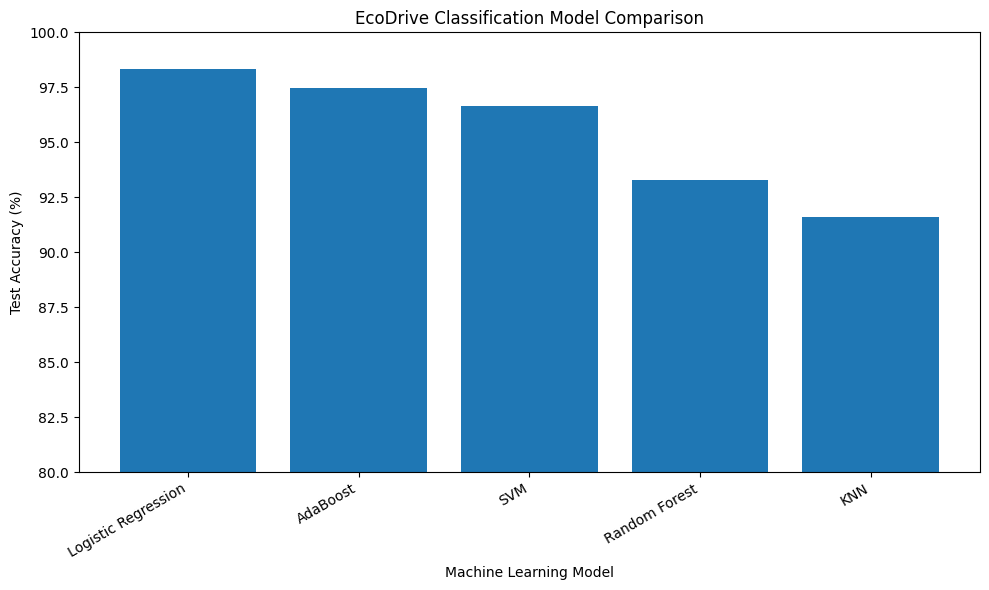

In [52]:
# ============================================================
# CLASSIFICATION ACCURACY COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    classification_results["Model"],
    classification_results["Accuracy (%)"]
)

plt.title("EcoDrive Classification Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Test Accuracy (%)")

plt.ylim(80, 100)
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [53]:
# ============================================================
# BEST CLASSIFICATION MODEL
# ============================================================

best_classification = classification_results.iloc[0]

print("Best Classification Model:")
print(best_classification["Model"])

print(
    "Test Accuracy:",
    str(best_classification["Accuracy (%)"]) + "%"
)

print("\nLogistic Regression Mean CV Accuracy: 97.80%")
print("AdaBoost Mean CV Accuracy: 95.43%")
print("Random Forest Mean CV Accuracy: 91.54%")

Best Classification Model:
Logistic Regression
Test Accuracy: 98.32%

Logistic Regression Mean CV Accuracy: 97.80%
AdaBoost Mean CV Accuracy: 95.43%
Random Forest Mean CV Accuracy: 91.54%


# Regression Analysis: EV Resale Price Prediction

The second objective of Project EcoDrive is to predict the Fair Market Resale Price of pre-owned electric vehicles. Regression models are evaluated using MAE, RMSE, and R² Score.

In [54]:
# ============================================================
# REGRESSION TRAIN-TEST SPLIT
# ============================================================

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_processed_df,
    y_regression,
    test_size=0.20,
    random_state=42
)

print("Regression Training Features:", X_reg_train.shape)
print("Regression Testing Features:", X_reg_test.shape)

print("Regression Training Target:", y_reg_train.shape)
print("Regression Testing Target:", y_reg_test.shape)

Regression Training Features: (472, 20)
Regression Testing Features: (119, 20)
Regression Training Target: (472,)
Regression Testing Target: (119,)


In [55]:
# ============================================================
# LINEAR REGRESSION
# ============================================================

linear_reg = LinearRegression()

linear_reg.fit(X_reg_train, y_reg_train)

linear_predictions = linear_reg.predict(X_reg_test)

linear_mae = mean_absolute_error(
    y_reg_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_reg_test,
    linear_predictions
)

print("Linear Regression Results")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R² Score:", round(linear_r2, 4))

Linear Regression Results
MAE: 2235.29
RMSE: 2862.49
R² Score: 0.8364


In [56]:
# ============================================================
# RANDOM FOREST REGRESSION
# ============================================================

rf_reg = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_reg.fit(X_reg_train, y_reg_train)

rf_predictions = rf_reg.predict(X_reg_test)

rf_mae = mean_absolute_error(
    y_reg_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_reg_test,
    rf_predictions
)

print("Random Forest Regression Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 4))

Random Forest Regression Results
MAE: 2688.13
RMSE: 3332.63
R² Score: 0.7782


In [57]:
# ============================================================
# REGRESSION MODEL COMPARISON
# ============================================================

regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2
    ]
})

regression_results = regression_results.round(4)

print("Regression Model Comparison:")
display(regression_results)

Regression Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,2235.2920,2862.4950,0.8364
1,Random Forest Regression,2688.1335,3332.6301,0.7782


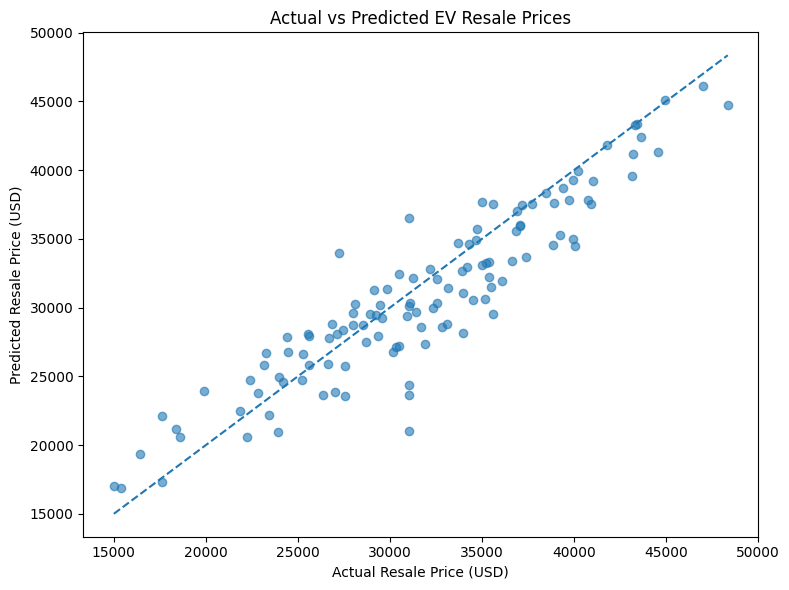

In [58]:
# ============================================================
# ACTUAL VS PREDICTED RESALE PRICE
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_test,
    linear_predictions,
    alpha=0.6
)

minimum = min(
    y_reg_test.min(),
    linear_predictions.min()
)

maximum = max(
    y_reg_test.max(),
    linear_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted EV Resale Prices")
plt.xlabel("Actual Resale Price (USD)")
plt.ylabel("Predicted Resale Price (USD)")

plt.tight_layout()
plt.show()

In [59]:
# ============================================================
# FINAL REGRESSION RESULT
# ============================================================

print("Best Regression Model: Linear Regression")
print("MAE: $", round(linear_mae, 2))
print("RMSE: $", round(linear_rmse, 2))
print("R² Score:", round(linear_r2, 4))

print(
    "\nLinear Regression achieved the best regression "
    "performance with lower prediction errors and a "
    "higher R² score than Random Forest Regression."
)

Best Regression Model: Linear Regression
MAE: $ 2235.29
RMSE: $ 2862.49
R² Score: 0.8364

Linear Regression achieved the best regression performance with lower prediction errors and a higher R² score than Random Forest Regression.


# Final Conclusion

Project EcoDrive successfully developed an end-to-end machine learning pipeline for analyzing the pre-owned electric vehicle market. The project addressed two major objectives: predicting whether an EV listing has High Demand and estimating its Resale Price.

## Classification – High Demand Prediction

Five classification models were evaluated:

- Logistic Regression: 98.32% Test Accuracy
- KNN: 91.60% Test Accuracy
- SVM: 96.64% Test Accuracy
- Random Forest: 93.28% Test Accuracy
- AdaBoost: 97.48% Test Accuracy

Logistic Regression achieved the highest test accuracy of 98.32%. It also achieved a strong mean cross-validation accuracy of approximately 97.80%, indicating consistent performance across different folds.

AdaBoost was the strongest ensemble model, achieving 97.48% test accuracy and 95.43% mean cross-validation accuracy.

Therefore, Logistic Regression is recommended as the final classification model because it achieved the highest test accuracy while also demonstrating strong cross-validation performance.

## Regression – Resale Price Prediction

Two regression models were evaluated:

- Linear Regression: MAE = $2,235.29, RMSE = $2,862.49, R² = 0.8364
- Random Forest Regression: MAE = $2,688.13, RMSE = $3,332.63, R² = 0.7782

Linear Regression achieved lower prediction errors and a higher R² score. An R² score of 0.8364 indicates that the model explains approximately 83.64% of the variation in EV resale prices within the dataset.

Therefore, Linear Regression is recommended as the final regression model.

## Model Strengths and Weaknesses

Logistic Regression provided excellent classification performance while remaining simple and interpretable. KNN was easy to implement but produced lower accuracy. SVM achieved strong performance but is comparatively less interpretable. Random Forest can capture complex non-linear relationships but did not outperform the simpler classification models in this dataset. AdaBoost achieved excellent accuracy but remained slightly behind Logistic Regression.

For resale-price prediction, Linear Regression performed better than Random Forest Regression. Its strong performance is consistent with the structured relationships between resale price and variables such as battery capacity, battery health, vehicle age, and odometer readings in the dataset.

## Overall Outcome

The project successfully demonstrated data cleaning, median and mode imputation, IQR-based anomaly detection, feature engineering, One-Hot Encoding, Z-Score Standardization, RFE feature selection, Stratified K-Fold Cross-Validation, RandomizedSearchCV hyperparameter tuning, baseline classification, ensemble learning, regression analysis, model comparison, and final model selection.

Final recommended models:

**High Demand Classification: Logistic Regression — 98.32% Test Accuracy**

**Resale Price Regression: Linear Regression — R² = 0.8364**